# MovieLens 100K: Exploratory Data Analysis

This notebook explores the MovieLens 100K dataset to understand its structure, rating distributions, user and movie activity, and data quality before implementing recommendation models.

## 1. Dataset Overview

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import GENRE_COLS, load_movielens

sns.set_theme(style="whitegrid")

### Load Dataset

In [2]:
ratings, movies, users = load_movielens()

### Verify Dataset Dimensions

In [3]:
for name, df in zip(["Ratings", "Movies", "Users"], [ratings, movies, users]):
    print(f"{name}: {df.shape}")

Ratings: (100000, 4)
Movies: (1682, 24)
Users: (943, 5)


### Examine Unique Users and Movies

In [4]:
# We wish to determine the number of distinct users and movies in the ratings data.
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies:", ratings["movie_id"].nunique())
print("Total ratings:", len(ratings))

Unique users: 943
Unique movies: 1682
Total ratings: 100000


## 2. Rating Distribution

### Rating Frequencies

In [5]:
freq = ratings["rating"].value_counts().sort_index()
percentage = (freq / len(ratings)) * 100

rating_distribution = pd.DataFrame({
    "Frequency": freq,
    "Percentage (%)": percentage
})

display(rating_distribution)

,Frequency,Percentage (%)
rating,,
1,6110,6.110
2,11370,11.370
3,27145,27.145
4,34174,34.174
5,21201,21.201


### Descriptive Statistics

In [6]:
display(ratings["rating"].describe())

print("Median rating:", ratings["rating"].median())
print("Mode rating:", ratings["rating"].mode().tolist())

count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Median rating: 4.0
Mode rating: [4]


### Visualize Rating Distribution

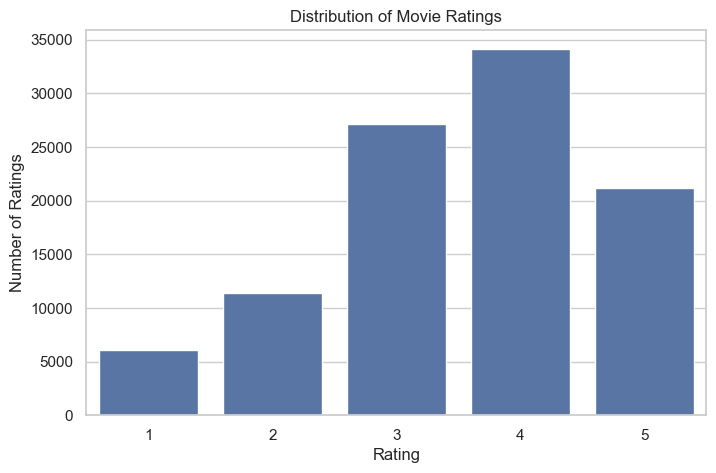

In [7]:
# Visualization of Rating Distribution
# This shows how frequently users assign each rating
plt.figure(figsize=(8, 5))
sns.barplot(x=freq.index, y=freq.values)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(range(5), [1, 2, 3, 4, 5])

plt.show()

## 3. Movie Activity Analysis

### Ratings per Movie

In [8]:
movie_activity = ratings.groupby("movie_id").size()

display(movie_activity.describe())

count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
dtype: float64

### Most Frequently Rated Movies

In [9]:
top_movies = (
    movie_activity
    .nlargest(10)
    .rename("rating_count")
    .reset_index()
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
    .sort_values("rating_count", ascending=False)
)

display(top_movies[["movie_id", "title", "rating_count"]])

,movie_id,title,rating_count
0,50,Star Wars (1977),583
1,258,Contact (1997),509
2,100,Fargo (1996),508
3,181,Return of the Jedi (1983),507
4,294,Liar Liar (1997),485
5,286,"English Patient, The (1996)",481
6,288,Scream (1996),478
7,1,Toy Story (1995),452
8,300,Air Force One (1997),431
9,121,Independence Day (ID4) (1996),429


### Movie Activity Distribution

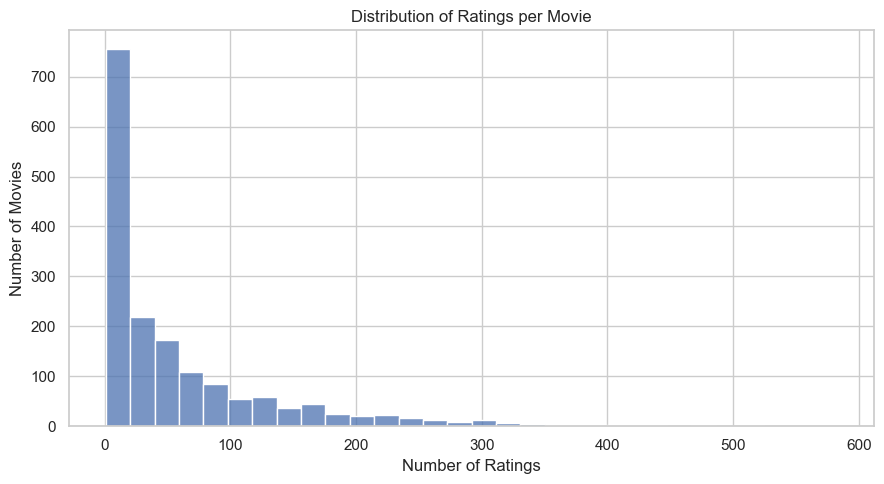

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(movie_activity, bins=30)

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

## 4. User Activity Analysis

### Ratings per User

In [11]:
user_activity = ratings.groupby("user_id").size()

display(user_activity.describe())

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64

### Most Active Users

In [12]:
top_users = (
    user_activity
    .nlargest(10)
    .rename("rating_count")
    .reset_index()
)

display(top_users)

,user_id,rating_count
0,405,737
1,655,685
2,13,636
3,450,540
4,276,518
5,416,493
6,537,490
7,303,484
8,234,480
9,393,448


### User Activity Distribution

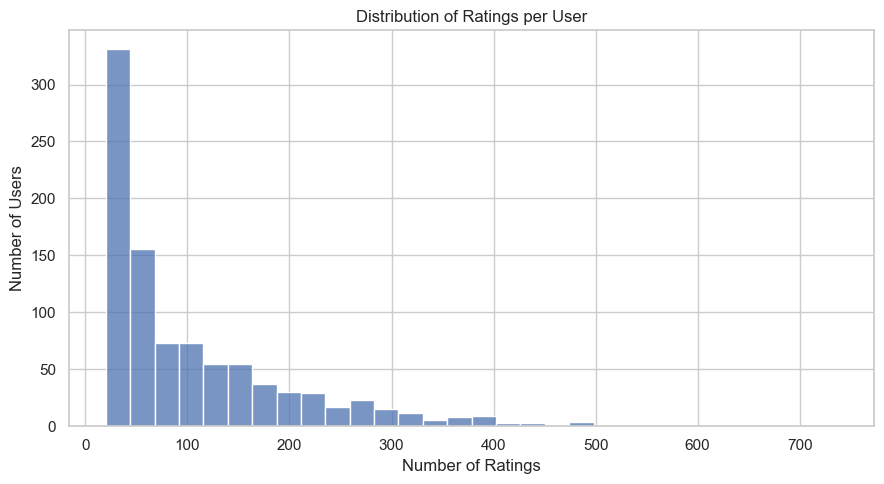

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(user_activity, bins=30)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

## 5. Data Quality Assessment

### Missing Values

In [14]:
print("Missing values in ratings:")
display(ratings.isnull().sum())

print("Missing values in movies:")
display(movies.isnull().sum())

print("Missing values in users:")
display(users.isnull().sum())

Missing values in ratings:


user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Missing values in movies:


movie_id                 0
title                    0
release_date             1
video_release_date    1682
imdb_url                 3
unknown                  0
Action                   0
Adventure                0
Animation                0
Children's               0
Comedy                   0
Crime                    0
Documentary              0
Drama                    0
Fantasy                  0
Film-Noir                0
Horror                   0
Musical                  0
Mystery                  0
Romance                  0
Sci-Fi                   0
Thriller                 0
War                      0
Western                  0
dtype: int64

Missing values in users:


user_id       0
age           0
gender        0
occupation    0
zip_code      0
dtype: int64

### Duplicate Records

In [15]:
print("Duplicate rating records:", ratings.duplicated().sum())
print("Duplicate movie records:", movies.duplicated().sum())
print("Duplicate user records:", users.duplicated().sum())

print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(subset=["user_id", "movie_id"]).sum()
)

dup_titles = movies[movies["title"].duplicated(keep=False)].sort_values("title")
print("Rows sharing a duplicate movie title:", len(dup_titles))
print("Distinct movie titles appearing multiple times:", dup_titles["title"].nunique())
display(dup_titles[["movie_id", "title", "release_date"]].head(10))

Duplicate rating records: 0


Duplicate movie records: 0
Duplicate user records: 0
Duplicate user-movie pairs: 0
Rows sharing a duplicate movie title: 36
Distinct movie titles appearing multiple times: 18


,movie_id,title,release_date
572,573,Body Snatchers (1993),01-Jan-1993
669,670,Body Snatchers (1993),01-Jan-1993
1644,1645,"Butcher Boy, The (1998)",01-Jan-1998
1649,1650,"Butcher Boy, The (1998)",01-Jan-1998
1233,1234,Chairman of the Board (1998),01-Jan-1998
1653,1654,Chairman of the Board (1998),01-Jan-1998
245,246,Chasing Amy (1997),01-Jan-1997
267,268,Chasing Amy (1997),01-Jan-1997
308,309,Deceiver (1997),01-Jan-1997
1605,1606,Deceiver (1997),01-Jan-1997


### Invalid Ratings

In [16]:
invalid_ratings = ratings[
    ~ratings["rating"].between(1, 5)
]

print("Invalid ratings:", len(invalid_ratings))
display(invalid_ratings.head())

Invalid ratings: 0


,user_id,movie_id,rating,timestamp


### Dataset Consistency

In [17]:
missing_users = set(ratings["user_id"]) - set(users["user_id"])
missing_movies = set(ratings["movie_id"]) - set(movies["movie_id"])

print("User IDs without metadata:", len(missing_users))
print("Movie IDs without metadata:", len(missing_movies))

User IDs without metadata: 0
Movie IDs without metadata: 0


## 6. Genre, Sparsity, and Modeling Readiness

### Interaction Matrix Sparsity and Temporal Span

User-movie matrix size: 943 x 1682 = 1,586,126 cells
Observed ratings:       100,000 (6.30% filled)
Matrix sparsity:        93.70%


Earliest rating: 1997-09-20 03:05:10
Latest rating:   1998-04-22 23:10:38
Collection span: 214 days


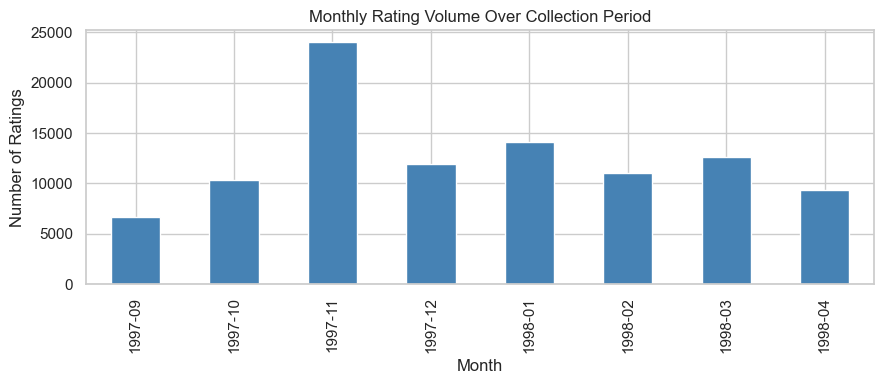

In [18]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
sparsity = 1.0 - len(ratings) / (n_users * n_movies)
print(f"User-movie matrix size: {n_users} x {n_movies} = {n_users * n_movies:,} cells")
print(f"Observed ratings:       {len(ratings):,} ({100 * (1 - sparsity):.2f}% filled)")
print(f"Matrix sparsity:        {100 * sparsity:.2f}%")

timestamps = pd.to_datetime(ratings["timestamp"], unit="s")
span_days = (timestamps.max() - timestamps.min()).days
print(f"Earliest rating: {timestamps.min()}")
print(f"Latest rating:   {timestamps.max()}")
print(f"Collection span: {span_days} days")

monthly_counts = timestamps.dt.to_period("M").value_counts().sort_index()
plt.figure(figsize=(9, 4))
monthly_counts.plot(kind="bar", color="steelblue")
plt.title("Monthly Rating Volume Over Collection Period")
plt.xlabel("Month")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

### Positive Rating Split (Threshold >= 4)

In [19]:
is_positive = ratings["rating"] >= 4
pos_share = is_positive.mean() * 100
print(f"Positive ratings (>= 4): {is_positive.sum():,} ({pos_share:.2f}%)")
print(f"Negative/neutral (< 4):  {(~is_positive).sum():,} ({100 - pos_share:.2f}%)")

user_positives = (
    ratings.assign(positive=is_positive)
    .groupby("user_id")["positive"]
    .sum()
)
print("\nPositive ratings per user:")
display(user_positives.describe())
print("Users with 0 positive ratings:", int((user_positives == 0).sum()))

Positive ratings (>= 4): 55,375 (55.38%)
Negative/neutral (< 4):  44,625 (44.62%)

Positive ratings per user:


count    943.000000
mean      58.722163
std       54.701130
min        0.000000
25%       19.000000
50%       39.000000
75%       80.500000
max      378.000000
Name: positive, dtype: float64

Users with 0 positive ratings: 1


### Genre Distribution and Binary Feature Verification

Unique genre indicator values: [0, 1]
Movies with zero genre flags: 0
Movies tagged with 'unknown' genre: 2


,movie_id,title
266,267,unknown
1372,1373,Good Morning (1971)



Genres per movie:


count    1682.000000
mean        1.719976
std         0.868207
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         6.000000
dtype: float64

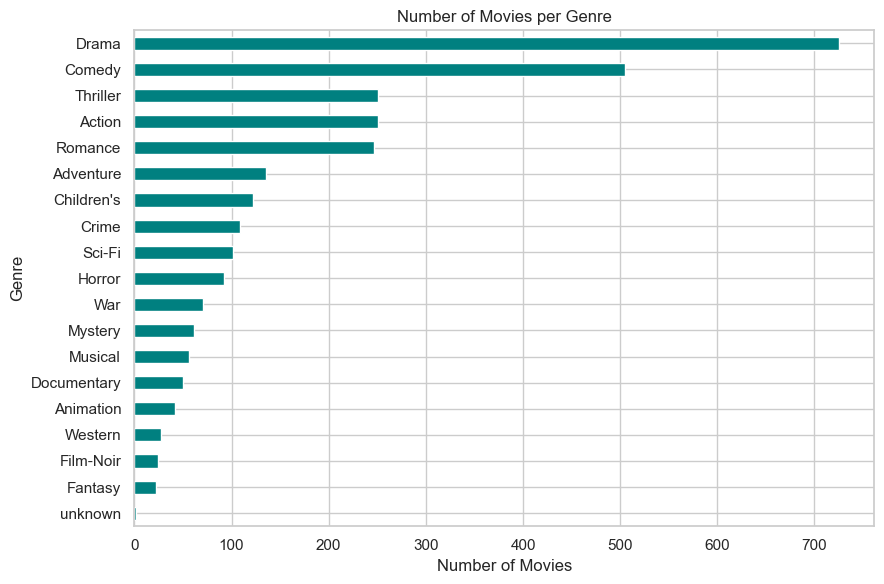

,movie_count
Drama,725
Comedy,505
Thriller,251
Action,251
Romance,247
Adventure,135
Children's,122
Crime,109
Sci-Fi,101
Horror,92


In [20]:
genre_values = movies[GENRE_COLS]
unique_vals = sorted(pd.unique(genre_values.to_numpy().ravel()).tolist())
genres_per_movie = genre_values.sum(axis=1)

print("Unique genre indicator values:", unique_vals)
print("Movies with zero genre flags:", int((genres_per_movie == 0).sum()))
unknown_movies = movies[movies["unknown"] == 1][["movie_id", "title"]]
print("Movies tagged with 'unknown' genre:", len(unknown_movies))
display(unknown_movies)

print("\nGenres per movie:")
display(genres_per_movie.describe())

genre_counts = genre_values.sum().sort_values(ascending=True)
plt.figure(figsize=(9, 6))
genre_counts.plot(kind="barh", color="teal")
plt.title("Number of Movies per Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

display(genre_counts.sort_values(ascending=False).rename("movie_count").to_frame())

### Long-Tail Coverage vs. Minimum Ratings Threshold

,min_ratings,eligible_movies,catalog_share_%,ratings_covered_%
0,1,1682,100.00,100.00
1,10,1152,68.49,97.95
2,25,872,51.84,93.50
3,50,603,35.85,83.72
4,100,338,20.10,64.82
5,200,118,7.02,33.68


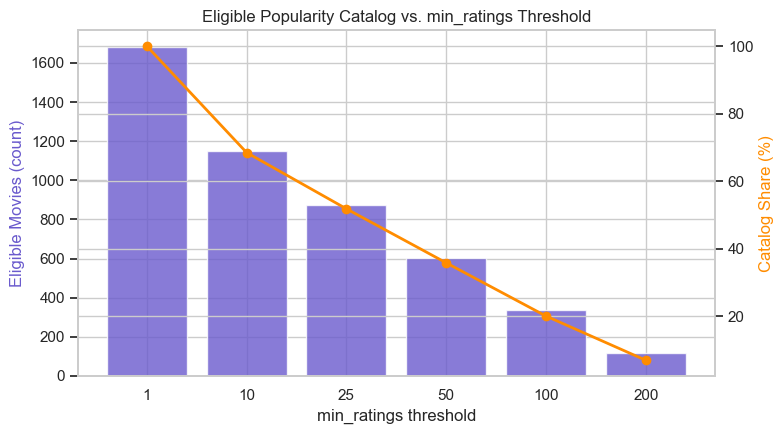

In [21]:
thresholds = [1, 10, 25, 50, 100, 200]
total_catalog = len(movies)
total_ratings = len(ratings)

coverage_rows = []
for min_r in thresholds:
    eligible = movie_activity[movie_activity >= min_r]
    coverage_rows.append({
        "min_ratings": min_r,
        "eligible_movies": len(eligible),
        "catalog_share_%": 100 * len(eligible) / total_catalog,
        "ratings_covered_%": 100 * eligible.sum() / total_ratings,
    })

coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df.round(2))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(coverage_df["min_ratings"].astype(str), coverage_df["eligible_movies"], color="slateblue", alpha=0.8)
ax1.set_xlabel("min_ratings threshold")
ax1.set_ylabel("Eligible Movies (count)", color="slateblue")
ax2 = ax1.twinx()
ax2.plot(coverage_df["min_ratings"].astype(str), coverage_df["catalog_share_%"], color="darkorange", marker="o", linewidth=2)
ax2.set_ylabel("Catalog Share (%)", color="darkorange")
plt.title("Eligible Popularity Catalog vs. min_ratings Threshold")
plt.tight_layout()
plt.show()

## 7. Key Findings

### Dataset Overview

The MovieLens 100K dataset contains **100,000 ratings** across **943 unique users** and **1,682 unique movies** (`Ratings`: `(100000, 4)`, `Movies`: `(1682, 24)`, `Users`: `(943, 5)`). Every movie and user in `u.item` and `u.user` appears in `u.data`. Out of 1,586,126 possible user-movie pairs (`943 × 1,682`), only 6.30% are observed, giving a matrix sparsity of **93.70%**. Ratings span **214 days** from `1997-09-20` to `1998-04-22`.

### Rating Distribution

Ratings skew positive across the 1–5 integer scale:
- **Mean:** `3.53` (`std = 1.13`), **Median:** `4.0`, **Mode:** `4`
- **Breakdown:** 4 stars is most frequent (`34,174` ratings, `34.17%`), followed by 3 (`27,145`, `27.15%`), 5 (`21,201`, `21.20%`), 2 (`11,370`, `11.37%`), and 1 (`6,110`, `6.11%`).
- Using `threshold=4` classifies **55,375 ratings (`55.38%`)** as positive and **44,625 (`44.62%`)** as negative or neutral, giving a balanced positive signal (median `39` positive ratings per user; 1 user has `0` positive ratings).

### Movie Activity

Rating volume per movie is heavily right-skewed (`mean = 59.45`, `std = 80.38`, `median = 27.0`, IQR `6.0–80.0`, range `1–583`). A small set of blockbusters receives hundreds of ratings—led by *Star Wars (1977)* (`583`), *Contact (1997)* (`509`), *Fargo (1996)* (`508`), *Return of the Jedi (1983)* (`507`), and *Liar Liar (1997)* (`485`)—while the bottom quarter of movies has 6 or fewer ratings. At `min_ratings=50`, **603 of 1,682 movies (`35.85%` of the catalog)** qualify for the popularity model while covering **`83.72%` of all ratings**.

### User Activity

User activity is also right-skewed (`mean = 106.04`, `std = 100.93`, `median = 65.0`, IQR `33.0–148.0`, range `20–737`). Every user has at least 20 ratings (ensuring every user retains at least 16 training ratings and 4 test ratings under an 80/20 time-based split), while the most active user (`user_id=405`) contributed `737` ratings.

### Data Quality & Genre Readiness

- **Missing values:** `0` missing values in `ratings` and `users`. In `movies`, `video_release_date` is empty for all `1,682` rows, `imdb_url` is missing `3` values, and `release_date` is missing `1` value; `movie_id`, `title`, and all 19 binary genre columns have `0` missing values.
- **Duplicates & validity:** `0` duplicate rows in `ratings`, `movies`, or `users`, `0` duplicate `(user_id, movie_id)` pairs, `0` ratings outside `[1, 5]`, and `0` unmatched user or movie IDs. However, `36` rows in `movies` share `18` duplicate titles under distinct `movie_id`s (e.g., *Body Snatchers (1993)*, *Chasing Amy (1997)*), which is why models must key on `movie_id` rather than `title`.
- **Genre features:** All 19 `GENRE_COLS` indicators take strictly binary `{0, 1}` values with `0` zero-genre movies (mean `1.72` genres per movie, median `2`, max `6`), led by *Drama* (`725`), *Comedy* (`505`), *Thriller* (`251`), *Action* (`251`), and *Romance* (`247`). Only 2 movies carry the `unknown` genre tag (`movie_id=267` *"unknown"* and `movie_id=1373` *"Good Morning (1971)"*).

### Conclusion

MovieLens 100K is clean, complete on core identifiers, and well-suited for our three recommenders: `93.70%` sparsity motivates recommendation over full-matrix inference, `min_ratings=50` guards the popularity baseline against noisy 1-rating outliers while capping its catalog reach at `35.85%` (603 movies), and dense binary genre tags (`1.72` genres/movie on average) enable cosine similarity scoring across the entire catalog—though shared single-genre vectors create similarity ties that require rating-count tie-breaking.